# Ví dụ train model với các biến thể Gradient (Stochatic, Batch, Mini Batch)

## 1. Tạo bộ dữ liệu

In [1]:
# Tạo bộ dữ liệu gồm 10 mẫu giá nhà, mỗi mẫu 1 đặc trưng diện tích và một nhãn giá cho hồi quy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
# Tạo dữ liệu mẫu
np.random.seed(0)

N = 100

X = np.random.rand(N) * 10
y = 4 * X + 3 + 3*np.random.randn(N)

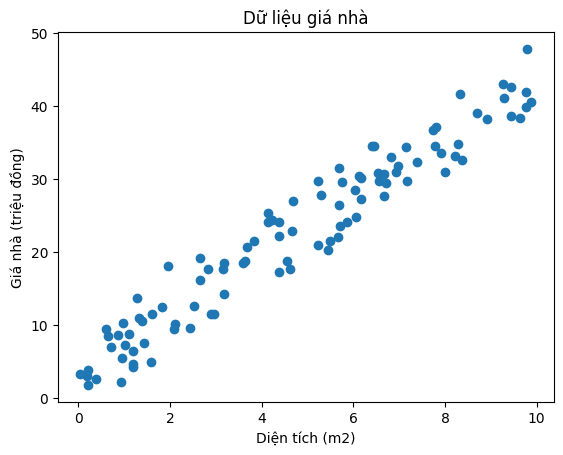

In [2]:
# Vẽ dữ liệu
plt.scatter(X, y)
plt.xlabel('Diện tích (m2)')
plt.ylabel('Giá nhà (triệu đồng)')
plt.title('Dữ liệu giá nhà')
plt.show()

## 2. Huấn luyện bằng các loss và gradient khác nhau

### 2.1 Sử dụng loss MSE

Hàm loss MSE:
$$
L(w,b)=\frac{1}{N}\sum_{1}^N{(y-(wx_i+b))^2}
$$

In [3]:
# Định nghĩa hàm loss MSE
def compute_loss(X, y, w, b):
    y_pred = w * X + b
    return np.mean((y - y_pred)**2)

Hàm Gradient của loss MSE

In [4]:
# Định nghĩa hàm tính Gradient
def compute_gradients(X, y, w, b):

    N = len(y)

    y_pred = w * X + b

    dw = (-2/N) * np.sum(X * (y - y_pred))
    db = (-2/N) * np.sum(y - y_pred)

    return dw, db

Hàm cập nhật tham số

In [5]:
# Định nghĩa hàm update tham số
def update_parameters(w, b, dw, db, learning_rate):

    w = w - learning_rate * dw
    b = b - learning_rate * db

    return w, b

Hàm Train

In [6]:
# Định nghĩa hàm huấn luyện
def train(X, y, batch_size, learning_rate=0.01, epochs=50):

    w = 0
    b = 0

    losses = []
    N = len(X)

    for epoch in range(epochs):

        indices = np.random.permutation(N)

        for i in range(0, N, batch_size):

            batch_idx = indices[i:i+batch_size]

            X_batch = X[batch_idx]
            y_batch = y[batch_idx]

            dw, db = compute_gradients(X_batch, y_batch, w, b)

            w, b = update_parameters(w, b, dw, db, learning_rate)

        loss = compute_loss(X, y, w, b)
        losses.append(loss)

    return w, b, losses

Batch Gradient Descent

In [7]:
w, b, loss_batch = train(X, y, batch_size=len(X), epochs=50)
# In tham số và loss
print(f"Tham số: w = {w:.4f}, b = {b:.4f}, loss = {loss_batch[-1]:.4f}")

Tham số: w = 4.3359, b = 1.3847, loss = 10.3435


Mini-batch Gradient Descent

In [8]:
w, b, loss_mini = train(X, y, batch_size=10, learning_rate= 0.01, epochs=50)
print(f"Tham số: w = {w:.4f}, b = {b:.4f}, loss = {loss_mini[-1]:.4f}")

Tham số: w = 3.7589, b = 3.4024, loss = 11.0704


Stochastic Gradient Descent

In [9]:
w, b, loss_sgd = train(X, y, batch_size=1, epochs=50)
print(f"Tham số: w = {w:.4f}, b = {b:.4f}, loss = {loss_sgd[-1]:.4f}")

Tham số: w = 4.5016, b = 3.6630, loss = 17.2233


So sánh hội tụ

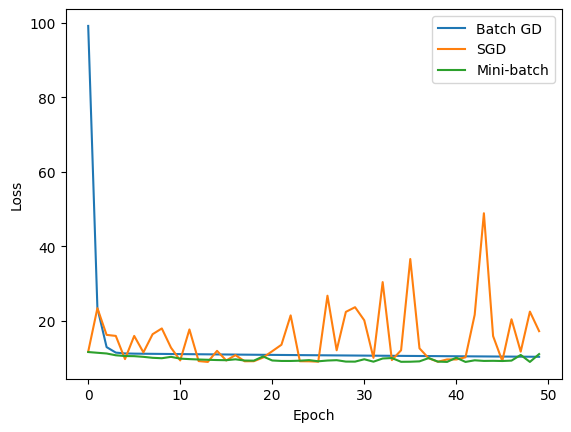

In [10]:
plt.plot(loss_batch, label="Batch GD")
plt.plot(loss_sgd, label="SGD")
plt.plot(loss_mini, label="Mini-batch")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### 2.2 Sử dụng loss MAE

Hàm loss MAE
$$
J(w,b)=\frac{1}{N}\sum_{i=1}^{N}\left|y_i-(wx_i+b)\right|
$$

In [13]:
def compute_loss(X, y, w, b):
    y_pred = w * X + b
    return np.mean(np.abs(y - y_pred))

Hàm tính Gradient của loss MAE
$$
dw = -\frac{1}{N}\sum x_i \cdot sign(y-y_{pred}) \\
db = -\frac{1}{N}\sum sign(y-y_{pred})
$$

In [14]:
def compute_gradients(X, y, w, b):

    N = len(y)

    y_pred = w * X + b

    error = y - y_pred

    dw = (-1/N) * np.sum(X * np.sign(error))
    db = (-1/N) * np.sum(np.sign(error))

    return dw, db

In [15]:
w, b, loss_sgd = train(X, y, batch_size=1)
print(f"Tham số: w = {w:.4f}, b = {b:.4f}, loss = {loss_sgd[-1]:.4f}")

Tham số: w = 3.9812, b = 3.4800, loss = 2.5553


### 2.3 Sử dụng loss Huber

### 2.4 Sử dụng loss MSE thêm điều chuẩn L2

$$
L(w,b)=\frac{1}{N}\sum_{1}^N{(y-(wx_i+b))^2} +\lambda w^2
$$

## 3. Huấn luyện và đánh giá mô hình

Chia dữ liệu Train/Test

In [16]:
import numpy as np
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Huấn luyện mô hình

In [17]:
w, b, losses = train(X_train, y_train, batch_size=10)

Dự đoán trên tập test

In [18]:
y_pred = w * X_test + b

Đánh giá mô hình

In [19]:
# Đánh giá bằng MAE
mae = np.mean(np.abs(y_test - y_pred))
# Đánh giá bằng MSE
mse = np.mean((y_test - y_pred)**2)

In kết quả

In [20]:
print(f"w = {w:.3f}")
print(f"b = {b:.3f}")

print(f"MAE = {mae:.3f}")
print(f"MSE = {mse:.3f}")

w = 4.357
b = 1.410
MAE = 2.611
MSE = 9.370


Minh họa

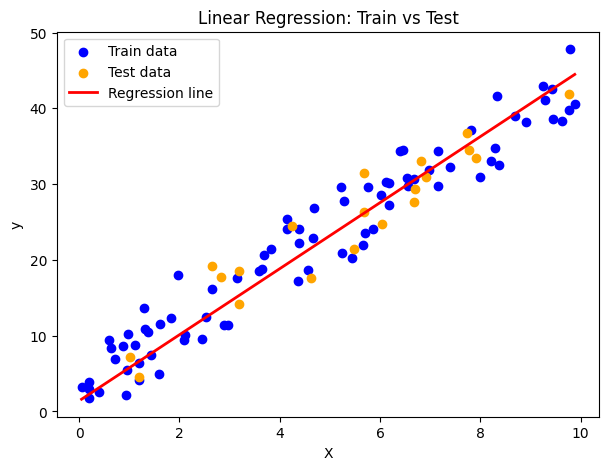

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# tạo trục x để vẽ đường hồi quy
x_line = np.linspace(min(X), max(X), 100)
y_line = w * x_line + b

plt.figure(figsize=(7,5))

# Tập train
plt.scatter(X_train, y_train, color='blue', label='Train data')

# Tập test
plt.scatter(X_test, y_test, color='orange', label='Test data')

# đường hồi quy
plt.plot(x_line, y_line, color='red', linewidth=2, label='Regression line')

plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression: Train vs Test")
plt.legend()

plt.show()

## 4. Sử dụng tập xác thực để điều chỉnh siêu tham số

Chia dữ liệu thành 3 tập

In [22]:
from sklearn.model_selection import train_test_split

# chia train + temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

# chia validation + test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

Huấn luyện mô hình trên train

In [23]:
w, b, losses = train(X_train, y_train, batch_size=10)

Đánh giá trên validation

In [24]:
y_val_pred = w * X_val + b

val_mse = np.mean((y_val - y_val_pred)**2)

print("Validation MSE:", val_mse)

Validation MSE: 9.529141182141943


Điều chỉnh siêu tham số

In [25]:
learning_rates = [0.001, 0.005, 0.01, 0.015, 0.02, 0.025, 0.03]

best_lr = None
best_loss = float("inf")

for lr in learning_rates:

    w, b, _ = train(X_train, y_train, batch_size=10, learning_rate=lr)

    y_val_pred = w * X_val + b
    val_loss = np.mean((y_val - y_val_pred)**2)

    print(f"lr={lr}  val_loss={val_loss:.3f}")

    if val_loss < best_loss:
        best_loss = val_loss
        best_lr = lr
print("Best lr:", best_lr)
print("Best validation loss:", best_loss)

lr=0.001  val_loss=357.914
lr=0.005  val_loss=9.799
lr=0.01  val_loss=9.588
lr=0.015  val_loss=9.292
lr=0.02  val_loss=8.972
lr=0.025  val_loss=8.858
lr=0.03  val_loss=8.714
Best lr: 0.03
Best validation loss: 8.714304577897023


Huấn luyện lại với siêu tham số tốt nhất

In [26]:
w, b, _ = train(X_train, y_train, batch_size=10, learning_rate=best_lr)

Đánh giá cuối cùng trên test

In [27]:
y_test_pred = w * X_test + b

test_mse = np.mean((y_test - y_test_pred)**2)

print("Test MSE:", test_mse)

Test MSE: 11.824544797955316


Đường cong xác thực


In [28]:
# Tập các siêu tham số cần thử
learning_rates = [0.001, 0.005, 0.01, 0.015, 0.02, 0.025, 0.03]
# Huấn luyện và lưu lỗi
train_errors = []
val_errors = []

for lr in learning_rates:

    w, b, _ = train(X_train, y_train, batch_size=10, learning_rate=lr)

    # lỗi train
    y_train_pred = w * X_train + b
    train_mse = np.mean((y_train - y_train_pred)**2)

    # lỗi validation
    y_val_pred = w * X_val + b
    val_mse = np.mean((y_val - y_val_pred)**2)

    train_errors.append(train_mse)
    val_errors.append(val_mse)

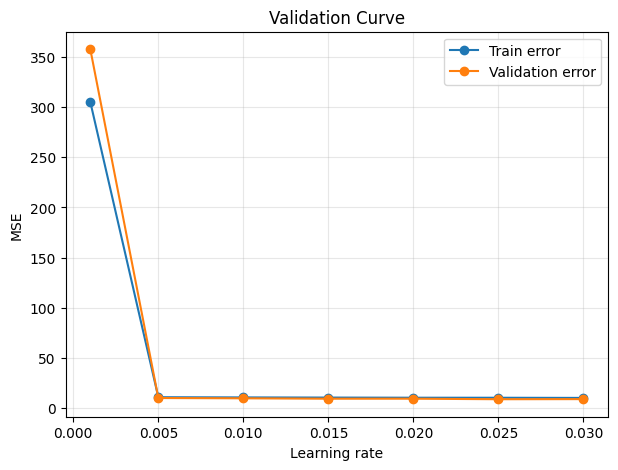

In [29]:
# Vẽ validation curve
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.plot(learning_rates, train_errors, marker='o', label='Train error')
plt.plot(learning_rates, val_errors, marker='o', label='Validation error')

plt.xlabel("Learning rate")
plt.ylabel("MSE")

plt.title("Validation Curve")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Sử dụng đường cong xác thực để tìm batch size?

## 5. Đường cong học tập (Learning Curve)

Thu thập dữ liệu để vẽ

Trong quá trình huấn luyện cần lưu:
- train loss mỗi epoch
- validation loss mỗi epoch

In [30]:
def train_Learn(X_train, y_train, X_val, y_val,
          batch_size=10, learning_rate=0.01, epochs=100):

    w = 0
    b = 0

    train_losses = []
    val_losses = []

    N = len(X_train)

    for epoch in range(epochs):

        indices = np.random.permutation(N)

        for i in range(0, N, batch_size):

            batch_idx = indices[i:i+batch_size]

            X_batch = X_train[batch_idx]
            y_batch = y_train[batch_idx]

            dw, db = compute_gradients(X_batch, y_batch, w, b)

            w, b = update_parameters(w, b, dw, db, learning_rate)

        # loss train
        train_loss = compute_loss(X_train, y_train, w, b)

        # loss validation
        val_loss = compute_loss(X_val, y_val, w, b)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

    return w, b, train_losses, val_losses

Huấn luyện mô hình

In [31]:
w, b, train_losses, val_losses = train_Learn(
    X_train, y_train,
    X_val, y_val,
    batch_size=10,
    learning_rate=0.005,
    epochs=100
)

Vẽ Learning Curve

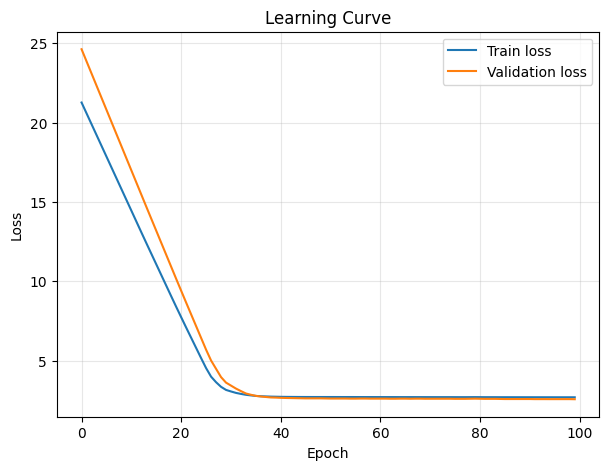

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.plot(train_losses, label="Train loss")
plt.plot(val_losses, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Learning Curve")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 6. Grid search cho learning rate và batch size

Danh sách siêu tham số cần thử

In [38]:
learning_rates = [0.001, 0.005, 0.01, 0.02]
batch_sizes = [1, 5, 10, 20]

Grid Search

In [40]:
best_lr = None
best_batch = None
best_loss = float("inf")
results = np.zeros((len(learning_rates), len(batch_sizes)))

for i, lr in enumerate(learning_rates):
    for j, batch in enumerate(batch_sizes):

        w, b, _ = train(
            X_train, 
            y_train, 
            batch_size=batch, 
            learning_rate=lr
        )

        y_val_pred = w * X_val + b
        val_loss = np.mean((y_val - y_val_pred)**2)
        
        results[i, j] = val_loss

        print(f"lr={lr:.4f}  batch={batch}  val_loss={val_loss:.4f}")

        if val_loss < best_loss:
            best_loss = val_loss
            best_lr = lr
            best_batch = batch

lr=0.0010  batch=1  val_loss=9.4943
lr=0.0010  batch=5  val_loss=114.5843
lr=0.0010  batch=10  val_loss=357.9141
lr=0.0010  batch=20  val_loss=533.7893
lr=0.0050  batch=1  val_loss=8.5258
lr=0.0050  batch=5  val_loss=9.5865
lr=0.0050  batch=10  val_loss=9.9077
lr=0.0050  batch=20  val_loss=47.0821
lr=0.0100  batch=1  val_loss=9.2745
lr=0.0100  batch=5  val_loss=9.3463
lr=0.0100  batch=10  val_loss=9.5247
lr=0.0100  batch=20  val_loss=9.8448
lr=0.0200  batch=1  val_loss=7.5176
lr=0.0200  batch=5  val_loss=8.0759
lr=0.0200  batch=10  val_loss=9.0431
lr=0.0200  batch=20  val_loss=9.4761


In kết quả tốt nhất

In [41]:
print("\nBest hyperparameters:")
print(f"learning rate = {best_lr}")
print(f"batch size = {best_batch}")
print(f"validation loss = {best_loss:.4f}")


Best hyperparameters:
learning rate = 0.02
batch size = 1
validation loss = 7.5176


Vẽ heatmap

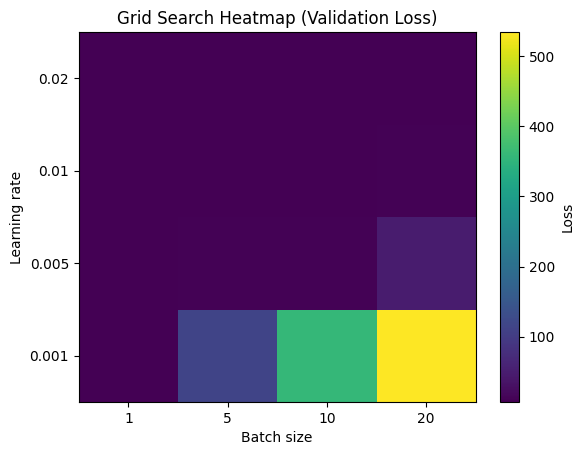

In [42]:
import matplotlib.pyplot as plt

plt.imshow(results, origin='lower', aspect='auto')

plt.xticks(range(len(batch_sizes)), batch_sizes)
plt.yticks(range(len(learning_rates)), learning_rates)

plt.xlabel("Batch size")
plt.ylabel("Learning rate")
plt.title("Grid Search Heatmap (Validation Loss)")

plt.colorbar(label="Loss")
plt.show()